In [1]:
import tensorflow as tf
from tensorflow.keras import datasets, layers, models
import matplotlib.pyplot as plt

(train_images, train_labels), (test_images, test_labels) = datasets.cifar10.load_data()

# Normalize pixel values to be between 0 and 1
train_images, test_images = train_images / 255.0, test_images / 255.0

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 1505s 9us/step


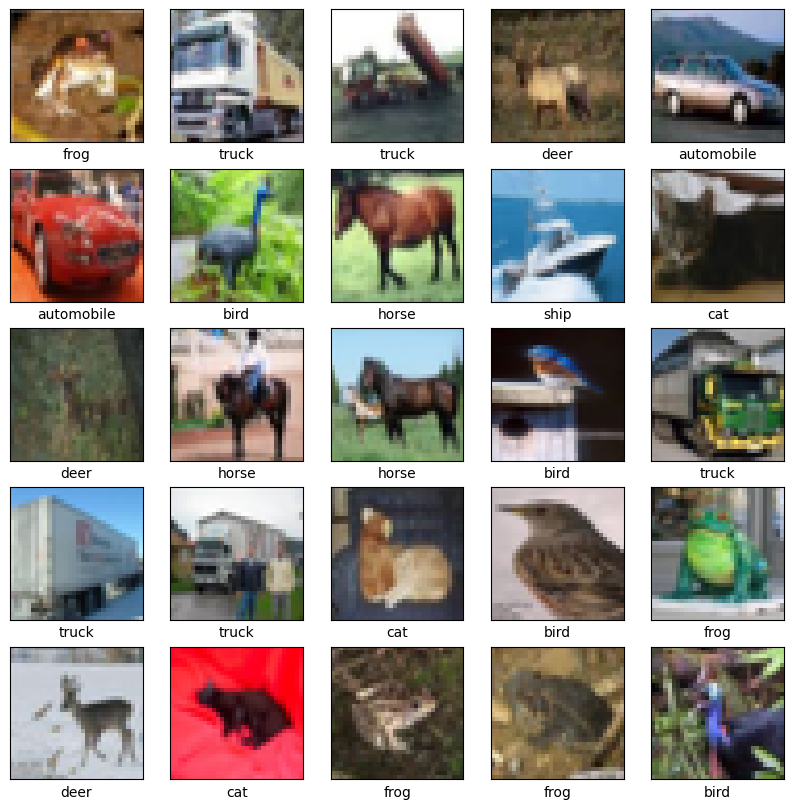

In [2]:
class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer',
               'dog', 'frog', 'horse', 'ship', 'truck']
plt.figure(figsize=(10,10))
for i in range(25):
    plt.subplot(5,5,i+1)
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    plt.imshow(train_images[i])
    # The CIFAR labels happen to be arrays,
    # which is why you need the extra index
    plt.xlabel(class_names[train_labels[i][0]])
plt.show()


In [3]:
model = models.Sequential()

model.add(layers.Conv2D(32,(3,3),activation='relu', input_shape=(32,32,3)))
model.add(layers.MaxPooling2D((2,2)))
model.add(layers.Conv2D(64,(3,3),activation='relu'))
model.add(layers.MaxPooling2D((2,2)))
model.add(layers.Conv2D(64,(3,3),activation='relu'))

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 13, 13, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 4, 4, 64)       │        36,928 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 56,320 (220.00 KB)

 Trainable params: 56,320 (220.00 KB)

 Non-trainable params: 0 (0.00 B)

In [4]:
model.add(layers.Flatten())
model.add(layers.Dense(64, activation='relu'))
model.add(layers.Dense(10))

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 13, 13, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 4, 4, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │        65,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 122,570 (478.79 KB)

 Trainable params: 122,570 (478.79 KB)

 Non-trainable params: 0 (0.00 B)

In [5]:
model.compile(optimizer='sgd',loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),metrics=['accuracy'])
history = model.fit(train_images, train_labels, epochs=10,validation_data=(test_images, test_labels))


Epoch 1/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 25s 11ms/step - accuracy: 0.2442 - loss: 2.0495 - val_accuracy: 0.3528 - val_loss: 1.8174
Epoch 2/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.3964 - loss: 1.6698 - val_accuracy: 0.4490 - val_loss: 1.5251
Epoch 3/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.4727 - loss: 1.4625 - val_accuracy: 0.4697 - val_loss: 1.4687
Epoch 4/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.5166 - loss: 1.3576 - val_accuracy: 0.4984 - val_loss: 1.3847
Epoch 5/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.5497 - loss: 1.2714 - val_accuracy: 0.5293 - val_loss: 1.3133
Epoch 6/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.5799 - loss: 1.1957 - val_accuracy: 0.5728 - val_loss: 1.1920
Epoch 7/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 11s 4ms/step - accuracy: 0.6012 - loss: 1.1317 - val_accuracy: 0.5630 - val_loss: 1.2114
Epoch 8/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.6241 - loss: 1.0714

313/313 - 1s - 4ms/step - accuracy: 0.6385 - loss: 1.0222


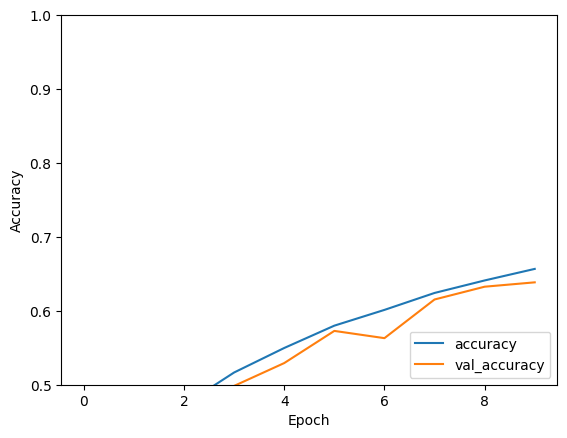

In [6]:
plt.plot(history.history['accuracy'], label='accuracy')
plt.plot(history.history['val_accuracy'], label = 'val_accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.ylim([0.5, 1])
plt.legend(loc='lower right')
test_loss, test_acc = model.evaluate(test_images,  test_labels, verbose=2)

In [7]:
print(test_acc)

0.6384999752044678


In [8]:
model.compile(optimizer='adam',loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),metrics=['accuracy'])
history = model.fit(train_images, train_labels, epochs=10,validation_data=(test_images, test_labels))

Epoch 1/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 13s 7ms/step - accuracy: 0.6356 - loss: 1.0389 - val_accuracy: 0.6419 - val_loss: 1.0180
Epoch 2/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.6926 - loss: 0.8779 - val_accuracy: 0.6679 - val_loss: 0.9593
Epoch 3/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.7292 - loss: 0.7724 - val_accuracy: 0.7049 - val_loss: 0.8505
Epoch 4/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.7587 - loss: 0.6861 - val_accuracy: 0.7053 - val_loss: 0.8603
Epoch 5/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.7859 - loss: 0.6099 - val_accuracy: 0.7140 - val_loss: 0.8365
Epoch 6/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.8093 - loss: 0.5463 - val_accuracy: 0.7097 - val_loss: 0.8887
Epoch 7/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.8247 - loss: 0.4964 - val_accuracy: 0.7146 - val_loss: 0.9050
Epoch 8/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.8426 - loss: 0.4462 -

313/313 - 1s - 3ms/step - accuracy: 0.6990 - loss: 1.0783


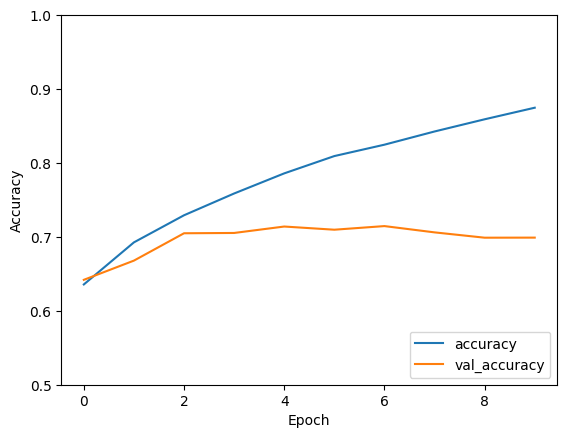

In [9]:
plt.plot(history.history['accuracy'], label='accuracy')
plt.plot(history.history['val_accuracy'], label = 'val_accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.ylim([0.5, 1])
plt.legend(loc='lower right')
test_loss, test_acc = model.evaluate(test_images,  test_labels, verbose=2)

In [10]:
print(test_acc)

0.6990000009536743


In [11]:
model.save('final_model.keras') #previously saved as 'final_model.h5", a legacy

unknown.jpg -> deer 56.6%, horse 33.0%, bird 6.3%
cat.jpg -> bird 34.7%, cat 31.7%, frog 30.4%
crow_crop.jpg -> bird 51.5%, frog 17.6%, deer 17.2%
red_object_001.jpg -> truck 56.6%, ship 41.0%, airplane 1.8%


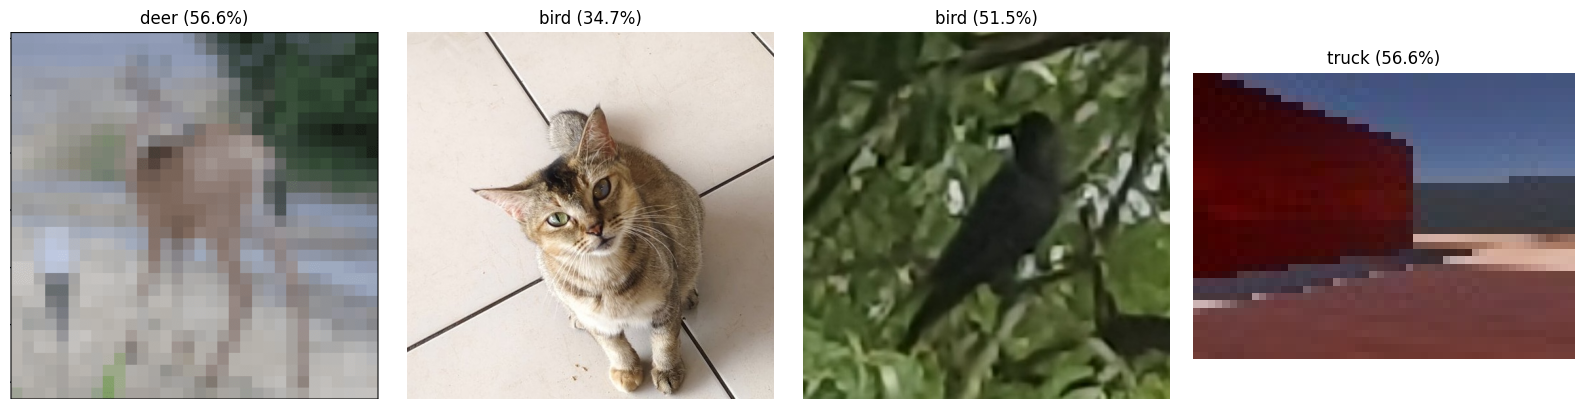

In [14]:
from tensorflow.keras.utils import load_img, img_to_array
from tensorflow.keras import models
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import os

class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer',
               'dog', 'frog', 'horse', 'ship', 'truck']

model = models.load_model('final_model.keras')


def load_image(filename):
    img = img_to_array(load_img(filename, target_size=(32, 32)))
    return img.reshape(1, 32, 32, 3).astype('float32') / 255.0


files = ['unknown.jpg', 'cat.jpg', 'crow_crop.jpg', 'red_object_001.jpg']
files = [f for f in files if os.path.exists(f)]

fig, ax = plt.subplots(1, len(files), figsize=(4 * len(files), 4), squeeze=False)
for a, f in zip(ax[0], files):
    probs = tf.nn.softmax(model.predict(load_image(f), verbose=0)[0]).numpy()
    k = np.argmax(probs)
    top3 = np.argsort(probs)[::-1][:3]
    print(f, '->', ', '.join(f'{class_names[i]} {probs[i] * 100:.1f}%' for i in top3))
    a.imshow(load_img(f))
    a.set_title(f'{class_names[k]} ({probs[k] * 100:.1f}%)')
    a.axis('off')
plt.tight_layout()
plt.savefig('predictions.png', dpi=200)
plt.show()


### Mount Google Drive
We will mount your Google Drive to `/content/drive` so that we can save the model file directly to it.

In [15]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


### Copy the Model File to Google Drive
Now, we'll copy `final_model.keras` to your drive (inside a folder named `CIFAR10_Models`, which will be created if it does not exist).

In [16]:
import shutil
import os

# Define destination directory on Google Drive
dest_dir = '/content/drive/MyDrive/CIFAR10_Models'
os.makedirs(dest_dir, exist_ok=True)

# Copy model file
source_file = 'final_model.keras'
dest_file = os.path.join(dest_dir, 'final_model.keras')

shutil.copy(source_file, dest_file)
print(f"Successfully saved {source_file} to {dest_file}!")

Successfully saved final_model.keras to /content/drive/MyDrive/CIFAR10_Models/final_model.keras!
